In [5]:
import json
import ssl
import urllib.parse
import urllib.request
import certifi
import pandas as pd 
params = urllib.parse.urlencode(
    {
        "start": "1",
        "limit": "10",
        "convert": "USD",
    }
)
request = urllib.request.Request(
    f"https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest?{params}",
    headers={
        "Accept": "application/json",
        "X-CMC_PRO_API_KEY": "e4c9c61cb51c4a5baeac898da652678a",
    },
)
context = ssl.create_default_context(cafile=certifi.where())
with urllib.request.urlopen(request, context=context) as response:
    data = json.load(response)
print(data)

{'data': [{'id': 1, 'name': 'Bitcoin', 'symbol': 'BTC', 'slug': 'bitcoin', 'infinite_supply': False, 'circulating_supply': 20098768, 'total_supply': 20098768, 'max_supply': 21000000, 'date_added': '2010-07-13T00:00:00.000Z', 'num_market_pairs': 12766, 'cmc_rank': 1, 'last_updated': '2026-10-15T19:55:00.000Z', 'tvl_ratio': None, 'platform': None, 'self_reported_circulating_supply': None, 'self_reported_market_cap': None, 'minted_market_cap': 1655055887940.41, 'quote': {'USD': {'price': 82346.13623782358, 'volume_24h': 42683317813.64813, 'cex_volume_24h': 42597561969.00777, 'dex_volume_24h': 85755844.64036135, 'volume_change_24h': 32.6627, 'percent_change_1h': 0.06670911, 'percent_change_24h': 0.75613317, 'percent_change_7d': 0.75665158, 'percent_change_30d': 8.35764488, 'percent_change_60d': 30.59537968, 'percent_change_90d': 28.43215346, 'market_cap': 1655055887940.409, 'market_cap_dominance': 59.8121, 'fully_diluted_market_cap': 1729268860994.3, 'tvl': None, 'last_updated': '2026-10-1

In [6]:
type(data)

dict

In [6]:
import pandas as pd 
pd.set_option('display.max_columns', None)

In [7]:
df = pd.json_normalize(data['data'])
df['timestamp'] = pd.to_datetime('now') #creating a time stamp to see when was the last time this API ran without relying on the last updated column.
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.009877e+07,2.009877e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12766,1,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,1.655056e+12,"[mineable, pow, sha-256, store-of-value, state...",82346.136238,4.268332e+10,4.259756e+10,8.575584e+07,32.6627,0.066709,0.756133,0.756652,8.357645,30.595380,28.432153,1.655056e+12,59.8121,1.729269e+12,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
1,1027,Ethereum,ETH,ethereum,True,1.221366e+08,1.221366e+08,NaN,2015-08-07T00:00:00.000Z,14046,2,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,2.997425e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",2454.158583,1.970742e+10,1.939290e+10,3.145140e+08,66.1729,0.274158,1.036830,-0.303403,1.865212,30.293093,33.203036,2.997425e+11,10.8324,2.997425e+11,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
2,825,Tether USDt,USDT,tether,True,1.840460e+11,1.893156e+11,NaN,2015-02-25T00:00:00.000Z,204225,3,2026-10-15T19:54:00.000Z,None,NaN,NaN,NaN,1.891314e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.999027,9.008199e+10,8.863726e+10,1.444731e+09,34.2668,0.003041,0.028128,-0.014180,-0.022509,0.005219,-0.030059,1.838669e+11,6.6448,1.891314e+11,None,2026-10-15T19:54:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-15 12:56:25.299319
3,1839,BNB,BNB,bnb,False,1.331585e+08,1.331585e+08,1.331585e+08,2017-07-25T00:00:00.000Z,3513,4,2026-10-15T19:54:00.000Z,None,NaN,NaN,NaN,9.755392e+10,"[marketplace, centralized-exchange, payments, ...",732.615161,1.688346e+09,1.675036e+09,1.331032e+07,39.8409,-0.073958,0.532081,0.259681,2.011051,21.053968,29.107265,9.755392e+10,3.5259,9.755392e+10,None,2026-10-15T19:54:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
4,52,XRP,XRP,xrp,False,6.312967e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1890,5,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,1.342651e+11,"[medium-of-exchange, enterprise-solutions, xrp...",1.342845,3.094679e+09,3.092833e+09,1.846178e+06,35.8339,0.178463,1.311914,-2.275799,3.143213,34.273654,23.130465,8.477334e+10,3.0636,1.342845e+11,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
5,3408,USDC,USDC,usd-coin,False,7.264960e+10,7.264960e+10,NaN,2018-10-08T00:00:00.000Z,46519,6,2026-10-15T19:54:00.000Z,None,NaN,6.090122e+10,6.089677e+10,7.264429e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999927,2.244872e+10,1.979400e+10,2.654725e+09,38.9040,0.004932,0.009940,0.010611,-0.001793,-0.000935,-0.005454,7.264429e+10,2.6256,7.264429e+10,None,2026-10-15T19:54:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-15 12:56:25.299319
6,5426,Solana,SOL,solana,True,5.892683e+08,6.358441e+08,NaN,2020-04-10T00:00:00.000Z,1184,7,2026-10-15T19:55:00.000Z,None,NaN,5.252369e+08,5.563712e+10,6.735348e+10,"[pos, platform, solana-ecosystem, cms-holdings...",105.927661,4.098028e+09,4.089853e+09,8.175313e+06,42.1060,0.112078,1.729603,-3.000597,8.315381,40.966103,41.033954,6.241981e+10,2.2558,6.735348e+10,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
7,1958,TRON,TRX,tron,True,9.499743e+10,9.499746e+10,NaN,2017-09-13T00:00:00.000Z,1387,8,2026-10-15T19:55:00.000Z,None,NaN,9.466789e+1

In [6]:
def api_runner():
    import json
import ssl
import urllib.parse
import urllib.request
import certifi
import pandas as pd 

params = urllib.parse.urlencode(
    {
        "start": "1",
        "limit": "10",
        "convert": "USD",
    }
)
request = urllib.request.Request(
    f"https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest?{params}",
    headers={
        "Accept": "application/json",
        "X-CMC_PRO_API_KEY": "e4c9c61cb51c4a5baeac898da652678a",
    },
)
context = ssl.create_default_context(cafile=certifi.where())
with urllib.request.urlopen(request, context=context) as response:
    data = json.load(response)
print(data)


df = pd.json_normalize(data['data'])
df['timestamp'] = pd.to_datetime('now') #creating a time stamp to see when was the last time this API ran without relying on the last updated column.
df

if not os.path.isfile(r"C:\Users\kelvi\Downloads\pythonScript\API.csv"):
    df.to_csv(r"C:\Users\kelvi\Downloads\pythonScript\API.csv", header='column_names')
else:
    df.to_csv(r"C:\Users\kelvi\Downloads\pythonScript\API.csv", mode='a', header=False)


{'data': [{'id': 1, 'name': 'Bitcoin', 'symbol': 'BTC', 'slug': 'bitcoin', 'infinite_supply': False, 'circulating_supply': 20098750, 'total_supply': 20098750, 'max_supply': 21000000, 'date_added': '2010-07-13T00:00:00.000Z', 'num_market_pairs': 12766, 'cmc_rank': 1, 'last_updated': '2026-10-15T19:50:00.000Z', 'tvl_ratio': None, 'platform': None, 'self_reported_circulating_supply': None, 'self_reported_market_cap': None, 'minted_market_cap': 1655457373540.4, 'quote': {'USD': {'price': 82366.18563544501, 'volume_24h': 42485447844.062645, 'cex_volume_24h': 42399630932.76697, 'dex_volume_24h': 85816911.29567195, 'volume_change_24h': 31.5826, 'percent_change_1h': 0.12498256, 'percent_change_24h': 0.86480188, 'percent_change_7d': 0.82283729, 'percent_change_30d': 8.52943324, 'percent_change_60d': 30.56006704, 'percent_change_90d': 28.42116414, 'market_cap': 1655457373540.4004, 'market_cap_dominance': 59.8464, 'fully_diluted_market_cap': 1729689898344.35, 'tvl': None, 'last_updated': '2026-10

In [7]:
import os 
from time import time
from time import sleep

for i in range(100):
    api_runner()
    print('API Runner ran successfully')
    sleep(60) #sleep for one minute
    exit()

API Runner ran successfully
API Runner ran successfully


KeyboardInterrupt: 

In [8]:

df70 = pd.read_csv(r"C:\Users\kelvi\Downloads\pythonScript\API.csv")
df70

,Unnamed: 0,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,0,1,Bitcoin,BTC,bitcoin,False,2.009875e+07,2.009875e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12766,1,2026-10-15T19:50:00.000Z,NaN,NaN,NaN,NaN,1.655457e+12,"['mineable', 'pow', 'sha-256', 'store-of-value...",82366.185635,4.248545e+10,4.239963e+10,8.581691e+07,31.5826,0.124983,0.864802,0.822837,8.529433,30.560067,28.421164,1.655457e+12,59.8464,1.729690e+12,NaN,2026-10-15T19:50:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:50:44.337510
1,1,1027,Ethereum,ETH,ethereum,True,1.221366e+08,1.221366e+08,NaN,2015-08-07T00:00:00.000Z,14046,2,2026-10-15T19:50:00.000Z,NaN,NaN,NaN,NaN,2.998256e+11,"['pos', 'smart-contracts', 'ethereum-ecosystem...",2454.838815,1.950195e+10,1.918798e+10,3.139731e+08,63.1921,0.286921,1.141780,-0.255825,2.104696,30.294834,33.150592,2.998256e+11,10.8390,2.998256e+11,NaN,2026-10-15T19:50:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:50:44.337510
2,2,825,Tether USDt,USDT,tether,True,1.840460e+11,1.893156e+11,NaN,2015-02-25T00:00:00.000Z,204224,3,2026-10-15T19:49:00.000Z,NaN,NaN,NaN,NaN,1.891227e+11,"['stablecoin', 'asset-backed-stablecoin', 'usd...",0.998982,9.005603e+10,8.860989e+10,1.446143e+09,34.3144,0.002087,0.016496,-0.022831,-0.011840,-0.015197,-0.033491,1.838585e+11,6.6467,1.891227e+11,NaN,2026-10-15T19:49:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-15 12:50:44.337510
3,3,1839,BNB,BNB,bnb,False,1.331585e+08,1.331585e+08,1.331585e+08,2017-07-25T00:00:00.000Z,3513,4,2026-10-15T19:49:00.000Z,NaN,NaN,NaN,NaN,9.755673e+10,"['marketplace', 'centralized-exchange', 'payme...",732.636220,1.688552e+09,1.675229e+09,1.332349e+07,39.9362,0.004217,0.574175,0.325350,2.087808,21.008908,29.112605,9.755673e+10,3.5263,9.755673e+10,NaN,2026-10-15T19:49:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:50:44.337510
4,4,52,XRP,XRP,xrp,False,6.312967e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1890,5,2026-10-15T19:49:00.000Z,NaN,NaN,NaN,NaN,1.342683e+11,"['medium-of-exchange', 'enterprise-solutions',...",1.342877,3.096645e+09,3.094798e+09,1.847657e+06,36.0101,0.192436,1.294789,-2.165836,3.433702,34.241671,23.167442,8.477535e+10,3.0647,1.342877e+11,NaN,2026-10-15T19:49:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:50:44.337510
5,5,3408,USDC,USDC,usd-coin,False,7.265436e+10,7.265436e+10,NaN,2018-10-08T00:00:00.000Z,46519,6,2026-10-15T19:49:00.000Z,NaN,NaN,6.090122e+10,6.089679e+10,7.264908e+10,"['medium-of-exchange', 'stablecoin', 'asset-ba...",0.999927,2.243697e+10,1.978163e+10,2.655336e+09,38.7225,0.001557,0.008979,0.009131,0.008348,-0.006376,-0.000335,7.264908e+10,2.6260,7.264908e+10,NaN,2026-10-15T19:49:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-15 12:50:44.337510
6,6,5426,Solana,SOL,solana,True,5.892683e+08,6.358441e+08,NaN,2020-04-10T00:00:00.000Z,1184,7,2026-10-15T19:50:00.000Z,NaN,NaN,5.252369e+08,5.563918e+10,6.735598e+10,"['pos', 'platform', 'solana-ecosystem', 'cms-h...",105.931586,4.098833e+09,4.090653e+09,8.180136e+06,42.1800,0.169737,1.753211,-2.878481,8.495389,40.904786,40.994919,6.242212e+10,2.2566,6.735598e+10,NaN,2026-10-15T19:50:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:50:44.337510
7,7,1958,TRON,TRX,tron,True,9.499743e+10,9.499746e+10,NaN,2017-09-13T00:00:00.000Z,1387,8,2026-10-15T19:50:00.000Z,NaN,NaN,

In [10]:
#chnaging the format of the data being presented.
pd.set_option('display.float_format', lambda x: '%.5f' % x)

In [11]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20098768.00000,20098768.00000,21000000.00000,2010-07-13T00:00:00.000Z,12766,1,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,1655055887940.40991,"[mineable, pow, sha-256, store-of-value, state...",82346.13624,42683317813.64813,42597561969.00777,85755844.64036,32.66270,0.06671,0.75613,0.75665,8.35764,30.59538,28.43215,1655055887940.40894,59.81210,1729268860994.30005,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
1,1027,Ethereum,ETH,ethereum,True,122136580.38769,122136580.38769,NaN,2015-08-07T00:00:00.000Z,14046,2,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,299742537034.22998,"[pos, smart-contracts, ethereum-ecosystem, coi...",2454.15858,19707417532.55922,19392903537.25071,314513995.30850,66.17290,0.27416,1.03683,-0.30340,1.86521,30.29309,33.20304,299742537034.22565,10.83240,299742537034.22998,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
2,825,Tether USDt,USDT,tether,True,184045984068.80310,189315553758.54089,NaN,2015-02-25T00:00:00.000Z,204225,3,2026-10-15T19:54:00.000Z,None,NaN,NaN,NaN,189131370786.87000,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99903,90081989437.64401,88637258389.33920,1444731048.30465,34.26680,0.00304,0.02813,-0.01418,-0.02251,0.00522,-0.03006,183866927802.18231,6.64480,189131370786.87000,None,2026-10-15T19:54:00.000Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-15 12:56:25.299319
3,1839,BNB,BNB,bnb,False,133158483.09000,133158483.09000,133158483.70000,2017-07-25T00:00:00.000Z,3513,4,2026-10-15T19:54:00.000Z,None,NaN,NaN,NaN,97553923584.85001,"[marketplace, centralized-exchange, payments, ...",732.61516,1688346112.69261,1675035795.24464,13310317.44797,39.84090,-0.07396,0.53208,0.25968,2.01105,21.05397,29.10727,97553923584.85263,3.52590,97553924031.75000,None,2026-10-15T19:54:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
4,52,XRP,XRP,xrp,False,63129671205.00000,99985607990.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1890,5,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,134265131238.14000,"[medium-of-exchange, enterprise-solutions, xrp...",1.34284,3094679085.72231,3092832907.59273,1846178.12958,35.83390,0.17846,1.31191,-2.27580,3.14321,34.27365,23.13047,84773336480.66238,3.06360,134284457470.69000,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
5,3408,USDC,USDC,usd-coin,False,72649597724.75688,72649597724.75688,NaN,2018-10-08T00:00:00.000Z,46519,6,2026-10-15T19:54:00.000Z,None,NaN,60901219650.23000,60896769069.76525,72644288588.38000,"[medium-of-exchange, stablecoin, asset-backed-...",0.99993,22448723094.48011,19793998294.82162,2654724799.65839,38.90400,0.00493,0.00994,0.01061,-0.00179,-0.00093,-0.00545,72644288588.38388,2.62560,72644288588.38000,None,2026-10-15T19:54:00.000Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-15 12:56:25.299319
6,5426,Solana,SOL,solana,True,589268258.37072,635844101.78943,NaN,2020-04-10T00:00:00.000Z,1184,7,2026-10-15T19:55:00.000Z,None,NaN,525236893.30000,55637115572.73589,67353478456.62000,"[pos, platform, solana-ecosystem, cms-holdings...",105.92766,4098028322.89004,4089853010.27300,8175312.61704,42.10600,0.11208,1.72960,-3.00060,8.31538,40.96610,41.0339

In [15]:
df3 = df.groupby('name',sort=False)[['quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_90d']].mean()
df3

,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_90d
name,,,,
Bitcoin,0.06671,0.75613,0.75665,28.43215
Ethereum,0.27416,1.03683,-0.30340,33.20304
Tether USDt,0.00304,0.02813,-0.01418,-0.03006
BNB,-0.07396,0.53208,0.25968,29.10727
XRP,0.17846,1.31191,-2.27580,23.13047
USDC,0.00493,0.00994,0.01061,-0.00545
Solana,0.11208,1.72960,-3.00060,41.03395
TRON,0.06573,-0.22135,-0.19363,2.93845
Zcash,0.82230,7.75552,6.41381,127.08733


In [16]:
df4 = df3.stack()
df4
#A better visualization of looking at the dataframe.

name                                     
Bitcoin      quote.USD.percent_change_1h      0.06671
             quote.USD.percent_change_24h     0.75613
             quote.USD.percent_change_7d      0.75665
             quote.USD.percent_change_90d    28.43215
Ethereum     quote.USD.percent_change_1h      0.27416
             quote.USD.percent_change_24h     1.03683
             quote.USD.percent_change_7d     -0.30340
             quote.USD.percent_change_90d    33.20304
Tether USDt  quote.USD.percent_change_1h      0.00304
             quote.USD.percent_change_24h     0.02813
             quote.USD.percent_change_7d     -0.01418
             quote.USD.percent_change_90d    -0.03006
BNB          quote.USD.percent_change_1h     -0.07396
             quote.USD.percent_change_24h     0.53208
             quote.USD.percent_change_7d      0.25968
             quote.USD.percent_change_90d    29.10727
XRP          quote.USD.percent_change_1h      0.17846
             quote.USD.percent_change_24

In [17]:
type(df4)
#covert back to a dataframe.

pandas.Series

In [18]:
df5=df4.to_frame(name='values')
df5

values
name                                              
Bitcoin     quote.USD.percent_change_1h    0.06671
            quote.USD.percent_change_24h   0.75613
            quote.USD.percent_change_7d    0.75665
            quote.USD.percent_change_90d  28.43215
Ethereum    quote.USD.percent_change_1h    0.27416
            quote.USD.percent_change_24h   1.03683
            quote.USD.percent_change_7d   -0.30340
            quote.USD.percent_change_90d  33.20304
Tether USDt quote.USD.percent_change_1h    0.00304
            quote.USD.percent_change_24h   0.02813
            quote.USD.percent_change_7d   -0.01418
            quote.USD.percent_change_90d  -0.03006
BNB         quote.USD.percent_change_1h   -0.07396
            quote.USD.percent_change_24h   0.53208
            quote.USD.percent_change_7d    0.25968
            quote.USD.percent_change_90d  29.10727
XRP         quote.USD.percent_change_1h    0.17846
            quote.USD.percent_change_24h   1.31191
            quote.USD.percent_change_7d   -2.27580
            quote.USD.percent_change_90d  23.13047
USDC        quote.USD.percent_change_1h    0.00493
            quote.USD.percent_change_24h   0.00994
            quote.USD.percent_change_7d    0.01061
            quote.USD.percent_change_90d  -0.00545
Solana      quote.USD.percent_change_1h    0.11208
            quote.USD.percent_change_24h   1.72960
            quote.USD.percent_change_7d   -3.00060
            quote.USD.percent_change_90d  41.03395
TRON        quote.USD.percent_change_1h    0.06573
            quote.USD.percent_change_24h  -0.22135
            quote.USD.percent_change_7d   -0.19363
            quote.USD.percent_change_90d   2.93845
Zcash       quote.USD.percent_change_1h    0.82230
            quote.USD.percent_change_24h   7.75552
            quote.USD.percent_change_7d    6.41381
            quote.USD.percent_change_90d 127.08733
Hyperliquid quote.USD.percent_change_1h    0.45546
            quote.USD.percent_change_24h   0.81036
            quote.USD.percent_change_7d   -2.78900
            quote.USD.percent_change_90d  36.00790

In [20]:
#double check df5
type(df5)
df5.count()

values    40
dtype: int64

In [22]:
index = pd.Index(range(40))

df6 = df5.reset_index()
df6

,name,level_1,values
0,Bitcoin,quote.USD.percent_change_1h,0.06671
1,Bitcoin,quote.USD.percent_change_24h,0.75613
2,Bitcoin,quote.USD.percent_change_7d,0.75665
3,Bitcoin,quote.USD.percent_change_90d,28.43215
4,Ethereum,quote.USD.percent_change_1h,0.27416
5,Ethereum,quote.USD.percent_change_24h,1.03683
6,Ethereum,quote.USD.percent_change_7d,-0.30340
7,Ethereum,quote.USD.percent_change_90d,33.20304
8,Tether USDt,quote.USD.percent_change_1h,0.00304
9,Tether USDt,quote.USD.percent_change_24h,0.02813


In [24]:
df7 = df6.rename(columns={'level_1':'percent_change'})
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,0.06671
1,Bitcoin,quote.USD.percent_change_24h,0.75613
2,Bitcoin,quote.USD.percent_change_7d,0.75665
3,Bitcoin,quote.USD.percent_change_90d,28.43215
4,Ethereum,quote.USD.percent_change_1h,0.27416
5,Ethereum,quote.USD.percent_change_24h,1.03683
6,Ethereum,quote.USD.percent_change_7d,-0.30340
7,Ethereum,quote.USD.percent_change_90d,33.20304
8,Tether USDt,quote.USD.percent_change_1h,0.00304
9,Tether USDt,quote.USD.percent_change_24h,0.02813


In [31]:
df7['percent_change'] = df7['percent_change'].replace(['quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_90d'],['1h','24h','7d','90d'])
df7
#cleaning up the name to have a better visualization in the graph.

,name,percent_change,values
0,Bitcoin,1h,0.06671
1,Bitcoin,24h,0.75613
2,Bitcoin,7d,0.75665
3,Bitcoin,90d,28.43215
4,Ethereum,1h,0.27416
5,Ethereum,24h,1.03683
6,Ethereum,7d,-0.30340
7,Ethereum,90d,33.20304
8,Tether USDt,1h,0.00304
9,Tether USDt,24h,0.02813


In [26]:
import seaborn as sns
import matplotlib.pyplot as plt 


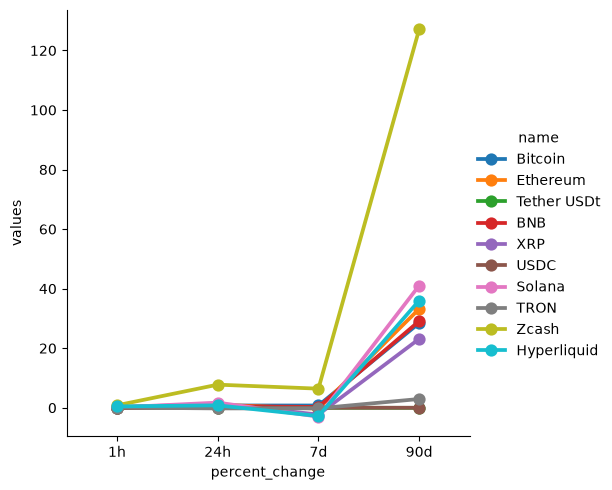

In [32]:
sns.catplot(x ='percent_change', y='values', hue='name',data=df7, kind='point')

In [37]:
df9= df[['name','quote.USD.price','timestamp']]
df9

,name,quote.USD.price,timestamp
0,Bitcoin,82346.13624,2026-10-15 12:56:25.299319
1,Ethereum,2454.15858,2026-10-15 12:56:25.299319
2,Tether USDt,0.99903,2026-10-15 12:56:25.299319
3,BNB,732.61516,2026-10-15 12:56:25.299319
4,XRP,1.34284,2026-10-15 12:56:25.299319
5,USDC,0.99993,2026-10-15 12:56:25.299319
6,Solana,105.92766,2026-10-15 12:56:25.299319
7,TRON,0.33222,2026-10-15 12:56:25.299319
8,Zcash,1240.75954,2026-10-15 12:56:25.299319
9,Hyperliquid,81.90513,2026-10-15 12:56:25.299319


In [43]:
# you want to look at certain cryptocurrency for example bitcoin, ethereum and solana
df9= df[['name','quote.USD.price','timestamp']]
df10 = df9.query("name in ['Bitcoin','Solana', 'Ethereum']")
df10

,name,quote.USD.price,timestamp
0,Bitcoin,82346.13624,2026-10-15 12:56:25.299319
1,Ethereum,2454.15858,2026-10-15 12:56:25.299319
6,Solana,105.92766,2026-10-15 12:56:25.299319


<Axes: xlabel='timestamp', ylabel='quote.USD.price'>

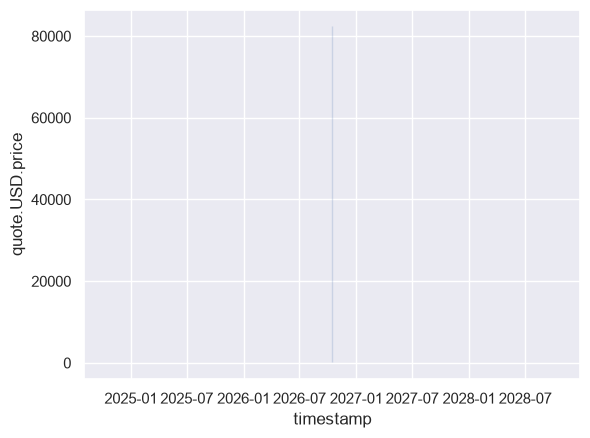

In [45]:
sns.set_theme(style="darkgrid")
sns.lineplot(x='timestamp', y='quote.USD.price', data = df10)

In [52]:
#reformatting the date added column to a cleaner visual
from datetime import datetime
df10 = df['date_added'] = pd.to_datetime(df['date_added']).dt.strftime('%m/%d/%Y')
df10
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20098768.00000,20098768.00000,21000000.00000,07/13/2010,12766,1,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,1655055887940.40991,"[mineable, pow, sha-256, store-of-value, state...",82346.13624,42683317813.64813,42597561969.00777,85755844.64036,32.66270,0.06671,0.75613,0.75665,8.35764,30.59538,28.43215,1655055887940.40894,59.81210,1729268860994.30005,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
1,1027,Ethereum,ETH,ethereum,True,122136580.38769,122136580.38769,NaN,08/07/2015,14046,2,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,299742537034.22998,"[pos, smart-contracts, ethereum-ecosystem, coi...",2454.15858,19707417532.55922,19392903537.25071,314513995.30850,66.17290,0.27416,1.03683,-0.30340,1.86521,30.29309,33.20304,299742537034.22565,10.83240,299742537034.22998,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
2,825,Tether USDt,USDT,tether,True,184045984068.80310,189315553758.54089,NaN,02/25/2015,204225,3,2026-10-15T19:54:00.000Z,None,NaN,NaN,NaN,189131370786.87000,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99903,90081989437.64401,88637258389.33920,1444731048.30465,34.26680,0.00304,0.02813,-0.01418,-0.02251,0.00522,-0.03006,183866927802.18231,6.64480,189131370786.87000,None,2026-10-15T19:54:00.000Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-15 12:56:25.299319
3,1839,BNB,BNB,bnb,False,133158483.09000,133158483.09000,133158483.70000,07/25/2017,3513,4,2026-10-15T19:54:00.000Z,None,NaN,NaN,NaN,97553923584.85001,"[marketplace, centralized-exchange, payments, ...",732.61516,1688346112.69261,1675035795.24464,13310317.44797,39.84090,-0.07396,0.53208,0.25968,2.01105,21.05397,29.10727,97553923584.85263,3.52590,97553924031.75000,None,2026-10-15T19:54:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
4,52,XRP,XRP,xrp,False,63129671205.00000,99985607990.00000,100000000000.00000,08/04/2013,1890,5,2026-10-15T19:55:00.000Z,None,NaN,NaN,NaN,134265131238.14000,"[medium-of-exchange, enterprise-solutions, xrp...",1.34284,3094679085.72231,3092832907.59273,1846178.12958,35.83390,0.17846,1.31191,-2.27580,3.14321,34.27365,23.13047,84773336480.66238,3.06360,134284457470.69000,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-15 12:56:25.299319
5,3408,USDC,USDC,usd-coin,False,72649597724.75688,72649597724.75688,NaN,10/08/2018,46519,6,2026-10-15T19:54:00.000Z,None,NaN,60901219650.23000,60896769069.76525,72644288588.38000,"[medium-of-exchange, stablecoin, asset-backed-...",0.99993,22448723094.48011,19793998294.82162,2654724799.65839,38.90400,0.00493,0.00994,0.01061,-0.00179,-0.00093,-0.00545,72644288588.38388,2.62560,72644288588.38000,None,2026-10-15T19:54:00.000Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-15 12:56:25.299319
6,5426,Solana,SOL,solana,True,589268258.37072,635844101.78943,NaN,04/10/2020,1184,7,2026-10-15T19:55:00.000Z,None,NaN,525236893.30000,55637115572.73589,67353478456.62000,"[pos, platform, solana-ecosystem, cms-holdings...",105.92766,4098028322.89004,4089853010.27300,8175312.61704,42.10600,0.11208,1.72960,-3.00060,8.31538,40.96610,41.03395,62419808304.65093,2.25580,67353478456.62000,None,2026-10-15T19:55:00.000Z,NaN,NaN,NaN,NaN,NaN,20